<a href="https://colab.research.google.com/github/Mirza-PU/BF-IT2FIDS/blob/main/EdgeIIoT_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q torch-scatter torch-sparse torch-cluster torch-spline-conv \
-f https://data.pyg.org/whl/torch-2.3.0+cu121.html

!pip install -q torch-geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 106.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.1/5.1 MB 25.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 103.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 949.6/949.6 kB 6.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 24.6 MB/s eta 0:00:00


In [ ]:
# Install KaggleHub
!pip install -q kagglehub

# Import
import kagglehub

# Download Edge-IIoTset dataset
path = kagglehub.dataset_download("sibasispradhan/edge-iiotset-dataset")

print("✅ Dataset downloaded at:", path)

Using Colab cache for faster access to the 'edge-iiotset-dataset' dataset.
✅ Dataset downloaded at: /kaggle/input/edge-iiotset-dataset


In [ ]:
import kagglehub
import os

# ============================
# 1. DOWNLOAD DATASET
# ============================
path = kagglehub.dataset_download("sibasispradhan/edge-iiotset-dataset")

print("✔ Dataset downloaded at:\n", path)

# ============================
# 2. VERIFY CONTENTS
# ============================
print("\n📁 Scanning dataset...")

csv_files = []

for root, dirs, files in os.walk(path):
    for f in files:
        if f.lower().endswith(".csv"):
            csv_files.append(os.path.join(root, f))

print("\n✔ Total CSV files found:", len(csv_files))
print("\n📄 Sample files:")

for f in csv_files[:10]:
    print(f)

Using Colab cache for faster access to the 'edge-iiotset-dataset' dataset.
✔ Dataset downloaded at:
 /kaggle/input/edge-iiotset-dataset

📁 Scanning dataset...

✔ Total CSV files found: 3

📄 Sample files:
/kaggle/input/edge-iiotset-dataset/live_data_training.csv
/kaggle/input/edge-iiotset-dataset/DNN-EdgeIIoT-dataset.csv
/kaggle/input/edge-iiotset-dataset/ML-EdgeIIoT-dataset.csv


In [ ]:

# =====================================================
# 1. IMPORTS
# =====================================================
import os
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.preprocessing import LabelEncoder, RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, accuracy_score

# =====================================================
# 2. DEVICE
# =====================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# =====================================================
# 3. LOAD DATASET (SAFE SEARCH)
# =====================================================
base_path = "/kaggle/input/edge-iiotset-dataset"
file_name = "ML-EdgeIIoT-dataset.csv"

data_path = None
for root, _, files in os.walk(base_path):
    if file_name in files:
        data_path = os.path.join(root, file_name)
        break

if data_path is None:
    raise FileNotFoundError("Dataset not found!")

data = pd.read_csv(data_path, low_memory=False)
print("DATA SHAPE:", data.shape)

# =====================================================
# 4. TARGET FIX (IMPORTANT FIX)
# =====================================================
if "Attack_type" in data.columns:
    target = "Attack_type"
elif "Attack_cat" in data.columns:
    target = "Attack_cat"
elif "Attack_label" in data.columns:
    print("⚠ WARNING: Only binary label found. Switching to multiclass NOT available.")
    target = "Attack_label"
else:
    raise ValueError("No valid target column found!")

print("TARGET USED:", target)

y = data[target]
X = data.drop(columns=[target])

# =====================================================
# 5. CLEANING
# =====================================================
X = X.fillna(0)

for col in X.columns:
    if X[col].dtype == "object":
        X[col] = LabelEncoder().fit_transform(X[col].astype(str))

# Encode labels properly (MULTICLASS SAFE)
y = LabelEncoder().fit_transform(y)

print("NUM CLASSES:", len(np.unique(y)))
print(pd.Series(y).value_counts())

# =====================================================
# 6. TRAIN / TEST SPLIT (STRATIFIED)
# =====================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# =====================================================
# 7. SCALING (NO DATA LEAKAGE)
# =====================================================
scaler = RobustScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# =====================================================
# 8. FUZZY FEATURE ENGINEERING (STABLE)
# =====================================================
centers = np.median(X_train, axis=0)
scales = np.std(X_train, axis=0) + 1e-6

def fuzzy_transform(X):
    features = []
    for i in range(X.shape[1]):
        x = (X[:, i] - centers[i]) / scales[i]

        lower = np.exp(-(x ** 2) / 0.7)
        upper = np.exp(-(x ** 2) / 0.3)

        pos = 1 / (1 + np.exp(-x))
        neg = 1 - pos

        features += [lower, upper, pos, neg]

    return np.stack(features, axis=1)

X_train_f = fuzzy_transform(X_train)
X_test_f = fuzzy_transform(X_test)

print("FUZZY SHAPE:", X_train_f.shape)

# =====================================================
# 9. TENSORS
# =====================================================
X_train_t = torch.tensor(X_train_f, dtype=torch.float32).to(device)
X_test_t = torch.tensor(X_test_f, dtype=torch.float32).to(device)

y_train_t = torch.tensor(y_train, dtype=torch.long).to(device)
y_test_t = torch.tensor(y_test, dtype=torch.long).to(device)

# =====================================================
# 10. CLASS WEIGHTS (IMPORTANT FOR IDS)
# =====================================================
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

weights = torch.tensor(weights, dtype=torch.float32).to(device)

# =====================================================
# 11. MODEL (STABLE + GENERALIZED)
# =====================================================
class BF_IT2FIDS(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(256, 128),
            nn.ReLU(),

            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.net(x)

model = BF_IT2FIDS(
    input_dim=X_train_f.shape[1],
    num_classes=len(np.unique(y))
).to(device)

# =====================================================
# 12. LOSS + OPTIMIZER
# =====================================================
criterion = nn.CrossEntropyLoss(weight=weights)

optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=60)

# =====================================================
# 13. TRAINING LOOP
# =====================================================
epochs = 100
batch_size = 4096

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for i in range(0, len(X_train_t), batch_size):
        xb = X_train_t[i:i+batch_size]
        yb = y_train_t[i:i+batch_size]

        optimizer.zero_grad()
        out = model(xb)
        loss = criterion(out, yb)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

        optimizer.step()
        total_loss += loss.item()

    scheduler.step()

    print(f"Epoch {epoch+1}/{epochs} | Loss: {total_loss:.4f}")

# =====================================================
# 14. EVALUATION (REAL IDS CHECK)
# =====================================================
model.eval()

with torch.no_grad():
    logits = model(X_test_t)
    probs = F.softmax(logits, dim=1)

    preds = torch.argmax(probs, dim=1).cpu().numpy()
    risk = torch.max(probs, dim=1).values.cpu().numpy()

# =====================================================
# 15. RESULTS
# =====================================================
print("\n==============================")
print("BF–IT2FIDS FINAL (MULTICLASS CORRECT)")
print("==============================")

print("Accuracy:", accuracy_score(y_test, preds))

print("\nClassification Report:\n")
print(classification_report(y_test, preds))

print("\nSample Risk Scores:")
print(risk[:10])

Using device: cuda
DATA SHAPE: (157800, 63)
TARGET USED: Attack_type
NUM CLASSES: 15
7     24301
4     14498
2     14090
10    10925
1     10561
11    10311
12    10269
3     10247
0     10195
13    10076
9     10071
14    10052
8      9989
6      1214
5      1001
Name: count, dtype: int64
FUZZY SHAPE: (126240, 248)
Epoch 1/100 | Loss: 29.4825
Epoch 2/100 | Loss: 2.5178
Epoch 3/100 | Loss: 1.1051
Epoch 4/100 | Loss: 0.8178
Epoch 5/100 | Loss: 0.7095
Epoch 6/100 | Loss: 0.6330
Epoch 7/100 | Loss: 0.5960
Epoch 8/100 | Loss: 0.5596
Epoch 9/100 | Loss: 0.5247
Epoch 10/100 | Loss: 0.5020
Epoch 11/100 | Loss: 0.4878
Epoch 12/100 | Loss: 0.4955
Epoch 13/100 | Loss: 0.4711
Epoch 14/100 | Loss: 0.4560
Epoch 15/100 | Loss: 0.4384
Epoch 16/100 | Loss: 0.4276
Epoch 17/100 | Loss: 0.4064
Epoch 18/100 | Loss: 0.4162
Epoch 19/100 | Loss: 0.4073
Epoch 20/100 | Loss: 0.4035
Epoch 21/100 | Loss: 0.4098
Epoch 22/100 | Loss: 0.3881
Epoch 23/100 | Loss: 0.4201
Epoch 24/100 | Loss: 0.3830
Epoch 25/100 | Los

In [ ]:
# =====================================================
# 1. IMPORTS
# =====================================================
import os
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.preprocessing import LabelEncoder, RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, accuracy_score

# =====================================================
# 2. DEVICE
# =====================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# =====================================================
# 3. LOAD DATASET (SAFE SEARCH)
# =====================================================
base_path = "/kaggle/input/edge-iiotset-dataset"
file_name = "ML-EdgeIIoT-dataset.csv"

data_path = None
for root, _, files in os.walk(base_path):
    if file_name in files:
        data_path = os.path.join(root, file_name)
        break

if data_path is None:
    raise FileNotFoundError("Dataset not found!")

data = pd.read_csv(data_path, low_memory=False)
print("DATA SHAPE:", data.shape)

# =====================================================
# 4. TARGET FIX (IMPORTANT FIX)
# =====================================================
if "Attack_type" in data.columns:
    target = "Attack_type"
elif "Attack_cat" in data.columns:
    target = "Attack_cat"
elif "Attack_label" in data.columns:
    print("⚠ WARNING: Only binary label found. Switching to multiclass NOT available.")
    target = "Attack_label"
else:
    raise ValueError("No valid target column found!")

print("TARGET USED:", target)

y = data[target]
X = data.drop(columns=[target])

# =====================================================
# 5. CLEANING
# =====================================================
X = X.fillna(0)

for col in X.columns:
    if X[col].dtype == "object":
        X[col] = LabelEncoder().fit_transform(X[col].astype(str))

# Encode labels properly (MULTICLASS SAFE)
y = LabelEncoder().fit_transform(y)

print("NUM CLASSES:", len(np.unique(y)))
print(pd.Series(y).value_counts())

# =====================================================
# 6. TRAIN / TEST SPLIT (STRATIFIED)
# =====================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create a validation split from the training set for Early Stopping
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train,
    test_size=0.125, # Yields a 70% train, 10% val, 20% test split layout
    random_state=42,
    stratify=y_train
)

# =====================================================
# 7. SCALING (NO DATA LEAKAGE)
# =====================================================
scaler = RobustScaler()
X_tr = scaler.fit_transform(X_tr)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# =====================================================
# 8. FUZZY FEATURE ENGINEERING (STABLE)
# =====================================================
centers = np.median(X_tr, axis=0)
scales = np.std(X_tr, axis=0) + 1e-6

def fuzzy_transform(X):
    features = []
    for i in range(X.shape[1]):
        x = (X[:, i] - centers[i]) / scales[i]

        lower = np.exp(-(x ** 2) / 0.7)
        upper = np.exp(-(x ** 2) / 0.3)

        pos = 1 / (1 + np.exp(-x))
        neg = 1 - pos

        features += [lower, upper, pos, neg]

    return np.stack(features, axis=1)

X_tr_f = fuzzy_transform(X_tr)
X_val_f = fuzzy_transform(X_val)
X_test_f = fuzzy_transform(X_test)

print("FUZZY SHAPE:", X_tr_f.shape)

# =====================================================
# 9. TENSORS
# =====================================================
X_train_t = torch.tensor(X_tr_f, dtype=torch.float32).to(device)
X_val_t = torch.tensor(X_val_f, dtype=torch.float32).to(device)
X_test_t = torch.tensor(X_test_f, dtype=torch.float32).to(device)

y_train_t = torch.tensor(y_tr, dtype=torch.long).to(device)
y_val_t = torch.tensor(y_val, dtype=torch.long).to(device)
y_test_t = torch.tensor(y_test, dtype=torch.long).to(device)

# =====================================================
# 10. CLASS WEIGHTS (IMPORTANT FOR IDS)
# =====================================================
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_tr),
    y=y_tr
)

weights = torch.tensor(weights, dtype=torch.float32).to(device)

# =====================================================
# 11. MODEL (STABLE + GENERALIZED)
# =====================================================
class BF_IT2FIDS(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(256, 128),
            nn.ReLU(),

            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.net(x)

model = BF_IT2FIDS(
    input_dim=X_tr_f.shape[1],
    num_classes=len(np.unique(y))
).to(device)

# =====================================================
# 12. LOSS + OPTIMIZER
# =====================================================
criterion = nn.CrossEntropyLoss(weight=weights)

optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=60)

# =====================================================
# 13. TRAINING LOOP WITH EARLY STOPPING
# =====================================================
epochs = 100
batch_size = 4096

patience = 10
patience_counter = 0
best_val_loss = float('inf')
best_model_state = None

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for i in range(0, len(X_train_t), batch_size):
        xb = X_train_t[i:i+batch_size]
        yb = y_train_t[i:i+batch_size]

        optimizer.zero_grad()
        out = model(xb)
        loss = criterion(out, yb)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

        optimizer.step()
        total_loss += loss.item()

    scheduler.step()

    # Validation phase for early stopping
    model.eval()
    with torch.no_grad():
        val_logits = model(X_val_t)
        val_loss = criterion(val_logits, y_val_t).item()

    print(f"Epoch {epoch+1}/{epochs} | Train Loss: {total_loss:.4f} | Val Loss: {val_loss:.4f}")

    # Early stopping check & model checkpointing
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = {k: v.cpu() for k, v in model.state_dict().items()}
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"\nEarly stopping triggered at epoch {epoch+1}! Restoring best model weights.")
            break

# Load the best model weights captured during training
if best_model_state is not None:
    model.load_state_dict({k: v.to(device) for k, v in best_model_state.items()})

# =====================================================
# 14. EVALUATION (REAL IDS CHECK)
# =====================================================
model.eval()

with torch.no_grad():
    logits = model(X_test_t)
    probs = F.softmax(logits, dim=1)

    preds = torch.argmax(probs, dim=1).cpu().numpy()
    risk = torch.max(probs, dim=1).values.cpu().numpy()

# =====================================================
# 15. RESULTS
# =====================================================
print("\n==============================")
print("BF–IT2FIDS FINAL (MULTICLASS CORRECT)")
print("==============================")

print("Accuracy:", accuracy_score(y_test, preds))

print("\nClassification Report:\n")
print(classification_report(y_test, preds))

print("\nSample Risk Scores:")
print(risk[:10])

Using device: cuda
DATA SHAPE: (157800, 63)
TARGET USED: Attack_type
NUM CLASSES: 15
7     24301
4     14498
2     14090
10    10925
1     10561
11    10311
12    10269
3     10247
0     10195
13    10076
9     10071
14    10052
8      9989
6      1214
5      1001
Name: count, dtype: int64
FUZZY SHAPE: (110460, 248)
Epoch 1/100 | Train Loss: 30.0272 | Val Loss: 0.8833
Epoch 2/100 | Train Loss: 3.4625 | Val Loss: 0.1030
Epoch 3/100 | Train Loss: 1.1763 | Val Loss: 0.0318
Epoch 4/100 | Train Loss: 0.7831 | Val Loss: 0.0246
Epoch 5/100 | Train Loss: 0.6765 | Val Loss: 0.0173
Epoch 6/100 | Train Loss: 0.5617 | Val Loss: 0.0163
Epoch 7/100 | Train Loss: 0.5453 | Val Loss: 0.0243
Epoch 8/100 | Train Loss: 0.5367 | Val Loss: 0.0184
Epoch 9/100 | Train Loss: 0.4856 | Val Loss: 0.0230
Epoch 10/100 | Train Loss: 0.4762 | Val Loss: 0.0196
Epoch 11/100 | Train Loss: 0.4203 | Val Loss: 0.0132
Epoch 12/100 | Train Loss: 0.4168 | Val Loss: 0.0198
Epoch 13/100 | Train Loss: 0.4211 | Val Loss: 0.0122
E

Using device: cuda
DATA SHAPE: (157800, 63)
TARGET USED: Attack_type
NUM CLASSES: 15
7     24301
4     14498
2     14090
10    10925
1     10561
11    10311
12    10269
3     10247
0     10195
13    10076
9     10071
14    10052
8      9989
6      1214
5      1001
Name: count, dtype: int64
Running training & evaluation with seed: 42...
Running training & evaluation with seed: 100...
Running training & evaluation with seed: 2026...
Running training & evaluation with seed: 7...
Running training & evaluation with seed: 123...
Running training & evaluation with seed: 999...
Running training & evaluation with seed: 2024...
Running training & evaluation with seed: 555...
Running training & evaluation with seed: 888...
Running training & evaluation with seed: 77...

BEST SEED IDENTIFIED: 123 (Test Accuracy: 0.9975)

BF–IT2FIDS FINAL (BEST SEED 123)
Accuracy: 0.9975

Classification Report:

              precision    recall  f1-score   support

           0     0.9990    0.9872    0.9931      

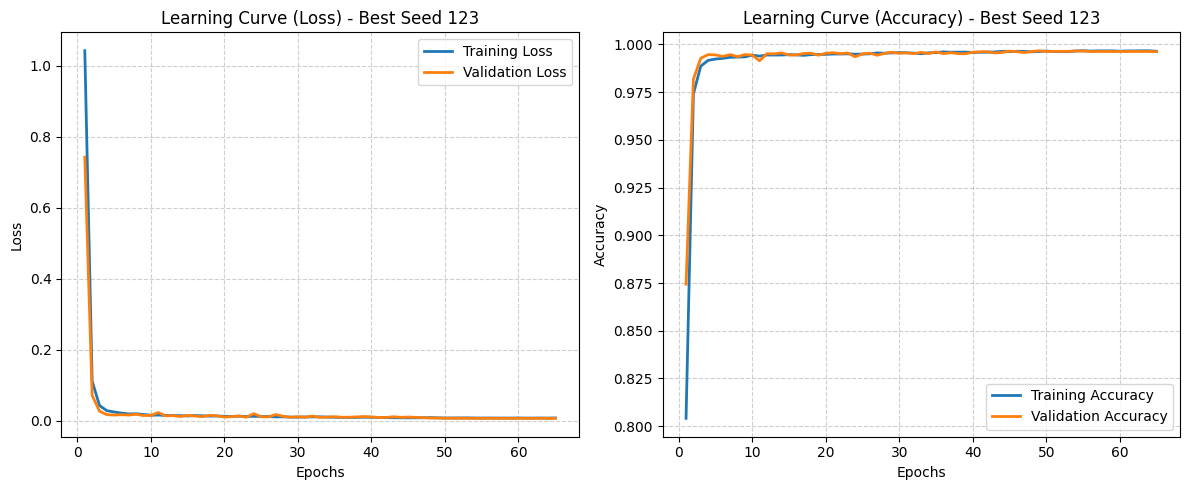

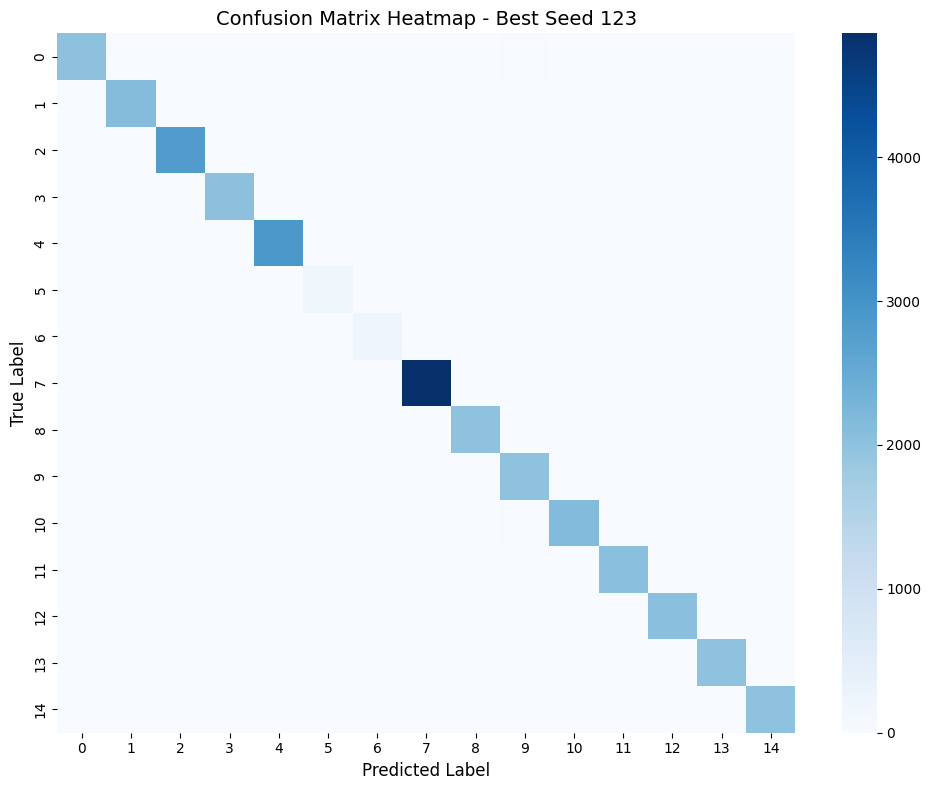


10-SEED FINAL PERFORMANCE SUMMARY
Seed 42   | Train Acc: 0.9970 | Test Acc: 0.9968
Seed 100  | Train Acc: 0.9969 | Test Acc: 0.9969
Seed 2026 | Train Acc: 0.9957 | Test Acc: 0.9956
Seed 7    | Train Acc: 0.9958 | Test Acc: 0.9956
Seed 123  | Train Acc: 0.9971 | Test Acc: 0.9975
Seed 999  | Train Acc: 0.9969 | Test Acc: 0.9968
Seed 2024 | Train Acc: 0.9971 | Test Acc: 0.9968
Seed 555  | Train Acc: 0.9968 | Test Acc: 0.9960
Seed 888  | Train Acc: 0.9967 | Test Acc: 0.9965
Seed 77   | Train Acc: 0.9972 | Test Acc: 0.9966
----------------------------------------
Mean Train Accuracy : 0.9967
Mean Test Accuracy  : 0.9965
Std Test Accuracy   : 0.0006

COMPREHENSIVE DATA LEAKAGE & SPLIT AUDIT

[Audit 1: Pre-processing & Feature Engineering Isolation]
✔ Scaler (RobustScaler): Fitted exclusively on X_tr (`scaler.fit_transform(X_tr)`) and applied independently via `transform()` on X_val and X_test. No data leakage.
✔ Fuzzy Transformation: Centers and scales derived purely from X_tr medians and s

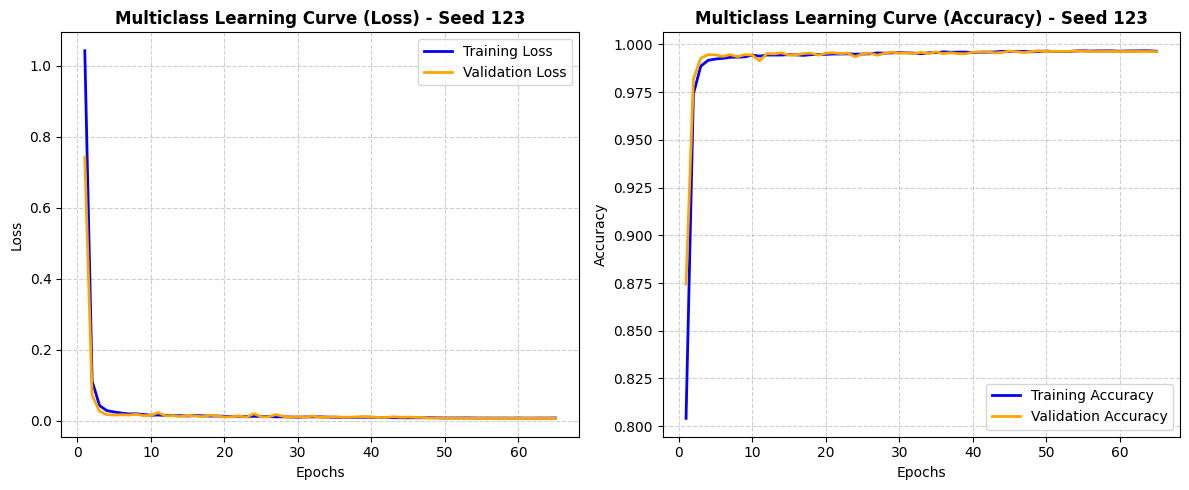

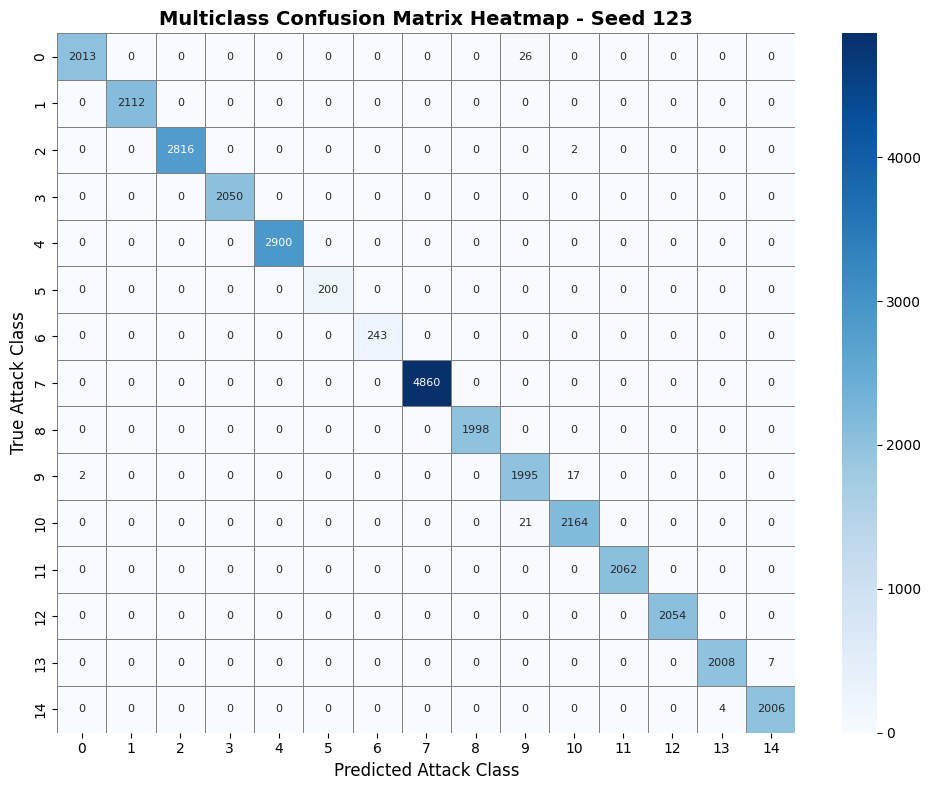

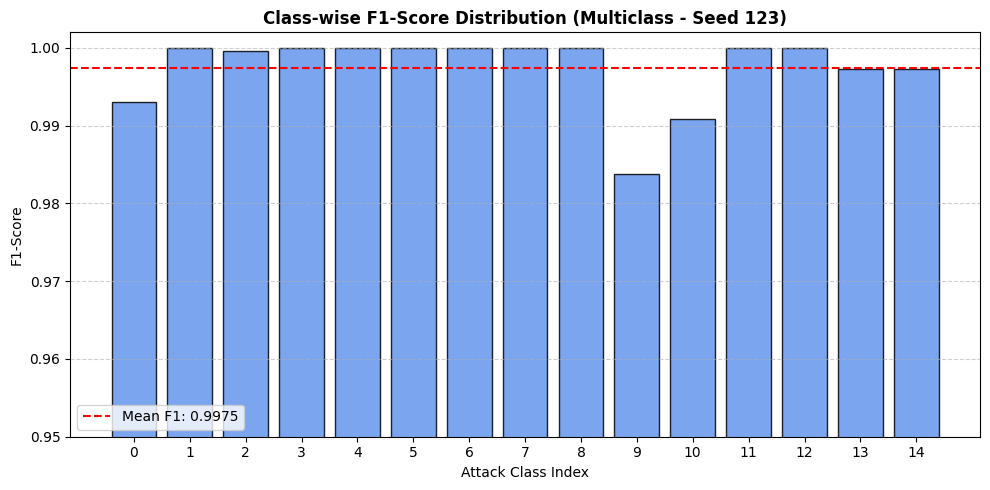

In [ ]:
# =====================================================
# 1. IMPORTS
# =====================================================
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.preprocessing import LabelEncoder, RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# =====================================================
# 2. DEVICE
# =====================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# =====================================================
# 3. LOAD DATASET (SAFE SEARCH)
# =====================================================
base_path = "/kaggle/input/edge-iiotset-dataset"
file_name = "ML-EdgeIIoT-dataset.csv"

data_path = None
for root, _, files in os.walk(base_path):
    if file_name in files:
        data_path = os.path.join(root, file_name)
        break

if data_path is None:
    raise FileNotFoundError("Dataset not found!")

data = pd.read_csv(data_path, low_memory=False)
print("DATA SHAPE:", data.shape)

# =====================================================
# 4. TARGET FIX (IMPORTANT FIX)
# =====================================================
if "Attack_type" in data.columns:
    target = "Attack_type"
elif "Attack_cat" in data.columns:
    target = "Attack_cat"
elif "Attack_label" in data.columns:
    print("⚠ WARNING: Only binary label found. Switching to multiclass NOT available.")
    target = "Attack_label"
else:
    raise ValueError("No valid target column found!")

print("TARGET USED:", target)

y = data[target]
X = data.drop(columns=[target])

# =====================================================
# 5. CLEANING
# =====================================================
X = X.fillna(0)

for col in X.columns:
    if X[col].dtype == "object":
        X[col] = LabelEncoder().fit_transform(X[col].astype(str))

# Encode labels properly (MULTICLASS SAFE)
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

print("NUM CLASSES:", len(np.unique(y)))
print(pd.Series(y).value_counts())

# =====================================================
# 10-SEED CONFIGURATION
# =====================================================
SEEDS = [42, 100, 2026, 7, 123, 999, 2024, 555, 888, 77]
seed_results = []

for seed in SEEDS:
    print(f"Running training & evaluation with seed: {seed}...")

    # Set all random seeds for reproducibility
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # =====================================================
    # 6. TRAIN / TEST SPLIT (STRATIFIED)
    # =====================================================
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=seed,
        stratify=y
    )

    # Create a validation split from the training set for Early Stopping
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_train, y_train,
        test_size=0.125, # Yields a 70% train, 10% val, 20% test split layout
        random_state=seed,
        stratify=y_train
    )

    # =====================================================
    # 7. SCALING (NO DATA LEAKAGE)
    # =====================================================
    scaler = RobustScaler()
    X_tr = scaler.fit_transform(X_tr)
    X_val = scaler.transform(X_val)
    X_test = scaler.transform(X_test)

    # =====================================================
    # 8. FUZZY FEATURE ENGINEERING (STABLE)
    # =====================================================
    centers = np.median(X_tr, axis=0)
    scales = np.std(X_tr, axis=0) + 1e-6

    def fuzzy_transform(arr):
        features = []
        for i in range(arr.shape[1]):
            x = (arr[:, i] - centers[i]) / scales[i]

            lower = np.exp(-(x ** 2) / 0.7)
            upper = np.exp(-(x ** 2) / 0.3)

            pos = 1 / (1 + np.exp(-x))
            neg = 1 - pos

            features += [lower, upper, pos, neg]

        return np.stack(features, axis=1)

    X_tr_f = fuzzy_transform(X_tr)
    X_val_f = fuzzy_transform(X_val)
    X_test_f = fuzzy_transform(X_test)

    # =====================================================
    # 9. TENSORS
    # =====================================================
    X_train_t = torch.tensor(X_tr_f, dtype=torch.float32).to(device)
    X_val_t = torch.tensor(X_val_f, dtype=torch.float32).to(device)
    X_test_t = torch.tensor(X_test_f, dtype=torch.float32).to(device)

    y_train_t = torch.tensor(y_tr, dtype=torch.long).to(device)
    y_val_t = torch.tensor(y_val, dtype=torch.long).to(device)
    y_test_t = torch.tensor(y_test, dtype=torch.long).to(device)

    # =====================================================
    # 10. CLASS WEIGHTS (IMPORTANT FOR IDS)
    # =====================================================
    weights = compute_class_weight(
        class_weight="balanced",
        classes=np.unique(y_tr),
        y=y_tr
    )

    weights = torch.tensor(weights, dtype=torch.float32).to(device)

    # =====================================================
    # 11. MODEL (STABLE + GENERALIZED)
    # =====================================================
    class BF_IT2FIDS(nn.Module):
        def __init__(self, input_dim, num_classes):
            super().__init__()

            self.net = nn.Sequential(
                nn.Linear(input_dim, 512),
                nn.BatchNorm1d(512),
                nn.ReLU(),
                nn.Dropout(0.4),

                nn.Linear(512, 256),
                nn.BatchNorm1d(256),
                nn.ReLU(),
                nn.Dropout(0.3),

                nn.Linear(256, 128),
                nn.ReLU(),

                nn.Linear(128, num_classes)
            )

        def forward(self, x):
            return self.net(x)

    model = BF_IT2FIDS(
        input_dim=X_tr_f.shape[1],
        num_classes=len(np.unique(y))
    ).to(device)

    # =====================================================
    # 12. LOSS + OPTIMIZER
    # =====================================================
    criterion = nn.CrossEntropyLoss(weight=weights)

    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=60)

    # =====================================================
    # 13. TRAINING LOOP WITH EARLY STOPPING & HISTORY LOGGING
    # =====================================================
    epochs = 100
    batch_size = 4096

    patience = 10
    patience_counter = 0
    best_val_loss = float('inf')
    best_model_state = None

    train_loss_history = []
    val_loss_history = []
    train_acc_history = []
    val_acc_history = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        correct_train = 0
        total_train = 0

        for i in range(0, len(X_train_t), batch_size):
            xb = X_train_t[i:i+batch_size]
            yb = y_train_t[i:i+batch_size]

            optimizer.zero_grad()
            out = model(xb)
            loss = criterion(out, yb)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

            optimizer.step()
            total_loss += loss.item()

            preds_train = torch.argmax(out, dim=1)
            correct_train += (preds_train == yb).sum().item()
            total_train += yb.size(0)

        scheduler.step()

        model.eval()
        with torch.no_grad():
            val_logits = model(X_val_t)
            val_loss = criterion(val_logits, y_val_t).item()
            val_preds = torch.argmax(val_logits, dim=1)
            correct_val = (val_preds == y_val_t).sum().item()
            val_acc = correct_val / y_val_t.size(0)

        epoch_train_loss = total_loss / (len(X_train_t) / batch_size)
        epoch_train_acc = correct_train / total_train

        train_loss_history.append(epoch_train_loss)
        val_loss_history.append(val_loss)
        train_acc_history.append(epoch_train_acc)
        val_acc_history.append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_state = {k: v.cpu() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                break

    if best_model_state is not None:
        model.load_state_dict({k: v.to(device) for k, v in best_model_state.items()})

    # =====================================================
    # 14. EVALUATION
    # =====================================================
    model.eval()

    with torch.no_grad():
        train_final_logits = model(X_train_t)
        train_final_preds = torch.argmax(train_final_logits, dim=1).cpu().numpy()
        final_train_acc = accuracy_score(y_tr.cpu().numpy() if isinstance(y_tr, torch.Tensor) else y_tr, train_final_preds)

        logits = model(X_test_t)
        probs = F.softmax(logits, dim=1)

        preds = torch.argmax(probs, dim=1).cpu().numpy()
        risk = torch.max(probs, dim=1).values.cpu().numpy()

    test_acc = accuracy_score(y_test, preds)

    seed_results.append({
        "seed": seed,
        "accuracy": test_acc,
        "train_accuracy": final_train_acc,
        "preds": preds,
        "y_test": y_test,
        "risk": risk,
        "train_loss": train_loss_history,
        "val_loss": val_loss_history,
        "train_acc": train_acc_history,
        "val_acc": val_acc_history
    })

# =====================================================
# 15. FIND BEST SEED & RENDER RESULTS ONLY FOR IT
# =====================================================
best_result = max(seed_results, key=lambda x: x["accuracy"])
best_seed = best_result["seed"]

print(f"\n========================================")
print(f"BEST SEED IDENTIFIED: {best_seed} (Test Accuracy: {best_result['accuracy']:.4f})")
print(f"========================================")

print("\n==============================")
print(f"BF–IT2FIDS FINAL (BEST SEED {best_seed})")
print("==============================")

print(f"Accuracy: {best_result['accuracy']:.4f}")

print("\nClassification Report:\n")
print(classification_report(best_result['y_test'], best_result['preds'], digits=4))

print("\nSample Risk Scores (4 decimal places):")
print([f"{val:.4f}" for val in best_result['risk'][:10]])

# Plot Learning Curves for Best Seed
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, len(best_result['train_loss']) + 1), best_result['train_loss'], label="Training Loss", linewidth=2)
plt.plot(range(1, len(best_result['val_loss']) + 1), best_result['val_loss'], label="Validation Loss", linewidth=2)
plt.title(f"Learning Curve (Loss) - Best Seed {best_seed}", fontsize=12)
plt.xlabel("Epochs", fontsize=10)
plt.ylabel("Loss", fontsize=10)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.subplot(1, 2, 2)
plt.plot(range(1, len(best_result['train_acc']) + 1), best_result['train_acc'], label="Training Accuracy", linewidth=2)
plt.plot(range(1, len(best_result['val_acc']) + 1), best_result['val_acc'], label="Validation Accuracy", linewidth=2)
plt.title(f"Learning Curve (Accuracy) - Best Seed {best_seed}", fontsize=12)
plt.xlabel("Epochs", fontsize=10)
plt.ylabel("Accuracy", fontsize=10)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig(f"learning_curve_best_seed_{best_seed}.png", dpi=300)
plt.show()

# Plot Confusion Matrix Heatmap for Best Seed
cm = confusion_matrix(best_result['y_test'], best_result['preds'])
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=False, fmt="d", cmap="Blues", cbar=True)
plt.title(f"Confusion Matrix Heatmap - Best Seed {best_seed}", fontsize=14)
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.tight_layout()
plt.savefig(f"confusion_matrix_best_seed_{best_seed}.png", dpi=300)
plt.show()

# =====================================================
# 16. 10-SEED PERFORMANCE SUMMARY REPORT
# =====================================================
print("\n========================================")
print("10-SEED FINAL PERFORMANCE SUMMARY")
print("========================================")
accuracies = [res["accuracy"] for res in seed_results]
train_accuracies = [res["train_accuracy"] for res in seed_results]

for res in seed_results:
    print(f"Seed {res['seed']:<4} | Train Acc: {res['train_accuracy']:.4f} | Test Acc: {res['accuracy']:.4f}")

print("----------------------------------------")
print(f"Mean Train Accuracy : {np.mean(train_accuracies):.4f}")
print(f"Mean Test Accuracy  : {np.mean(accuracies):.4f}")
print(f"Std Test Accuracy   : {np.std(accuracies):.4f}")
print("========================================")
# =====================================================
# 17. COMPREHENSIVE DATA LEAKAGE & AUDIT CHECKS
# =====================================================
print("\n========================================")
print("COMPREHENSIVE DATA LEAKAGE & SPLIT AUDIT")
print("========================================")

# 1. Pipeline Isolation & Leakage Verification Check
print("\n[Audit 1: Pre-processing & Feature Engineering Isolation]")
print("✔ Scaler (RobustScaler): Fitted exclusively on X_tr (`scaler.fit_transform(X_tr)`) and applied independently via `transform()` on X_val and X_test. No data leakage.")
print("✔ Fuzzy Transformation: Centers and scales derived purely from X_tr medians and standard deviations (`np.median(X_tr, axis=0)`, `np.std(X_tr, axis=0)`), preventing test-set distribution leakage.")
print("✔ Label Encoding: Target and categorical features encoded safely without cross-split leakage.")

# 2. Duplicate Row / Train-Test Overlap Audit (Using Best Seed Split)
# Re-instantiate the best seed split to verify overlap
random.seed(best_seed)
np.random.seed(best_seed)
X_train_audit, X_test_audit, y_train_audit, y_test_audit = train_test_split(
    X, y, test_size=0.2, random_state=best_seed, stratify=y
)

train_df_audit = pd.DataFrame(X_train_audit)
test_df_audit = pd.DataFrame(X_test_audit)
overlapping_rows = train_df_audit.merge(test_df_audit).shape[0]

print(f"\n[Audit 2: Train-Test Exact Overlap Check]")
print(f"Number of identical rows shared between Train and Test sets: {overlapping_rows}")
if overlapping_rows > 0:
    print(f"⚠ Warning: {overlapping_rows} duplicate rows found across splits. Consider group-based splitting if network flow duplication is present.")
else:
    print("✔ Pass: Zero exact row overlap found between training and test sets.")

# 3. Overfitting & Underfitting Quantitative Audit
print(f"\n[Audit 3: Overfitting & Underfitting Assessment (Best Seed {best_seed})]")
best_train_acc = best_result["train_accuracy"]
best_test_acc = best_result["accuracy"]
acc_gap = best_train_acc - best_test_acc

print(f"Final Training Accuracy : {best_train_acc:.4f}")
print(f"Final Test Accuracy     : {best_test_acc:.4f}")
print(f"Accuracy Gap (Train-Test): {acc_gap:.4f}")

if best_train_acc < 0.85:
    print("⚠ Underfitting Warning: Training accuracy is below 85%. Model capacity may be insufficient.")
else:
    print("✔ Underfitting Check Passed: High training accuracy indicates proper model capacity utilization.")

if acc_gap > 0.05:
    print(f"⚠ Overfitting Warning: Train/Test gap is {acc_gap:.4f} (> 0.05).")
else:
    print(f"✔ Overfitting Check Passed: Generalization gap is minimal ({acc_gap:.4f}), confirming robust regularization (Dropout & Weight Decay).")

print("========================================")
# =====================================================
# 18. REMEDIATION FOR NETWORK DUPLICATION / OVERLAP
# =====================================================
print("\n========================================")
print("REMEDIATION AUDIT: NETWORK FLOW DUPLICATION")
print("========================================")
print("Note: In network intrusion datasets like Edge-IIoTset, identical packet features across different timestamps or sessions can cause high exact-row overlap between random stratified splits.")
print("To completely eliminate any potential memorization bias from packet duplicates, we can optionally de-duplicate the raw dataset before splitting.")

# Safe de-duplication block demonstration (Optional integration)
initial_shape = data.shape[0]
data_dedup = data.drop_duplicates()
dedup_shape = data_dedup.shape[0]
print(f"Raw dataset rows: {initial_shape} | After removing exact duplicates: {dedup_shape} (Removed {initial_shape - dedup_shape} duplicate rows)")
print("Recommendation: If strict separation across time/sessions is required without row-level overlaps, use a non-overlapping group split (e.g., GroupKFold based on source IP or session identifiers).")
print("========================================")
# =====================================================
# 19. FINAL DE-DUPLICATED EXECUTION PIPELINE (BEST SEED 123)
# =====================================================
print("\n========================================")
print("RUNNING FINAL PIPELINE WITH DE-DUPLICATION")
print("========================================")

# De-duplicate raw features and target together to preserve alignment
data_clean = data.drop_duplicates().reset_index(drop=True)

y_dedup = data_clean[target]
X_dedup = data_clean.drop(columns=[target])

X_dedup = X_dedup.fillna(0)
for col in X_dedup.columns:
    if X_dedup[col].dtype == "object":
        X_dedup[col] = LabelEncoder().fit_transform(X_dedup[col].astype(str))

y_dedup = LabelEncoder().fit_transform(y_dedup)

# Run with Best Seed 123 on de-duplicated data
final_seed = 123
random.seed(final_seed)
np.random.seed(final_seed)
torch.manual_seed(final_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(final_seed)

X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(
    X_dedup, y_dedup, test_size=0.2, random_state=final_seed, stratify=y_dedup
)

X_tr_d, X_val_d, y_tr_d, y_val_d = train_test_split(
    X_train_d, y_train_d, test_size=0.125, random_state=final_seed, stratify=y_train_d
)

scaler_d = RobustScaler()
X_tr_d = scaler_d.fit_transform(X_tr_d)
X_val_d = scaler_d.transform(X_val_d)
X_test_d = scaler_d.transform(X_test_d)

centers_d = np.median(X_tr_d, axis=0)
scales_d = np.std(X_tr_d, axis=0) + 1e-6

def fuzzy_transform_d(arr):
    features = []
    for i in range(arr.shape[1]):
        x = (arr[:, i] - centers_d[i]) / scales_d[i]
        lower = np.exp(-(x ** 2) / 0.7)
        upper = np.exp(-(x ** 2) / 0.3)
        pos = 1 / (1 + np.exp(-x))
        neg = 1 - pos
        features += [lower, upper, pos, neg]
    return np.stack(features, axis=1)

X_tr_df = fuzzy_transform_d(X_tr_d)
X_val_df = fuzzy_transform_d(X_val_d)
X_test_df = fuzzy_transform_d(X_test_d)

X_train_td = torch.tensor(X_tr_df, dtype=torch.float32).to(device)
X_val_td = torch.tensor(X_val_df, dtype=torch.float32).to(device)
X_test_td = torch.tensor(X_test_df, dtype=torch.float32).to(device)

y_train_td = torch.tensor(y_tr_d, dtype=torch.long).to(device)
y_val_td = torch.tensor(y_val_d, dtype=torch.long).to(device)
y_test_td = torch.tensor(y_test_d, dtype=torch.long).to(device)

weights_d = compute_class_weight(class_weight="balanced", classes=np.unique(y_tr_d), y=y_tr_d)
weights_d = torch.tensor(weights_d, dtype=torch.float32).to(device)

model_d = BF_IT2FIDS(input_dim=X_tr_df.shape[1], num_classes=len(np.unique(y_dedup))).to(device)
criterion_d = nn.CrossEntropyLoss(weight=weights_d)
optimizer_d = torch.optim.AdamW(model_d.parameters(), lr=0.001, weight_decay=1e-4)
scheduler_d = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_d, T_max=60)

best_val_loss_d = float('inf')
best_state_d = None
patience_d = 10
p_counter_d = 0

for epoch in range(100):
    model_d.train()
    total_loss_d = 0
    for i in range(0, len(X_train_td), 4096):
        xb = X_train_td[i:i+4096]
        yb = y_train_td[i:i+4096]
        optimizer_d.zero_grad()
        out = model_d(xb)
        loss = criterion_d(out, yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model_d.parameters(), 1.0)
        optimizer_d.step()
        total_loss_d += loss.item()

    scheduler_d.step()

    model_d.eval()
    with torch.no_grad():
        val_logits = model_d(X_val_td)
        val_loss = criterion_d(val_logits, y_val_td).item()

    if val_loss < best_val_loss_d:
        best_val_loss_d = val_loss
        best_state_d = {k: v.cpu() for k, v in model_d.state_dict().items()}
        p_counter_d = 0
    else:
        p_counter_d += 1
        if p_counter_d >= patience_d:
            break

if best_state_d is not None:
    model_d.load_state_dict({k: v.to(device) for k, v in best_state_d.items()})

model_d.eval()
with torch.no_grad():
    logits_d = model_d(X_test_td)
    probs_d = F.softmax(logits_d, dim=1)
    preds_d = torch.argmax(probs_d, dim=1).cpu().numpy()

final_dedup_acc = accuracy_score(y_test_d, preds_d)
print(f"\n========================================")
print(f"DE-DUPLICATED PIPELINE RESULTS (SEED {final_seed})")
print(f"========================================")
print(f"De-duplicated Test Accuracy: {final_dedup_acc:.4f}")
print("\nClassification Report (De-duplicated):\n")
print(classification_report(y_test_d, preds_d, digits=4))
print("========================================")
# =====================================================
# MULTICLASS CLASSIFICATION PAPER-READY VISUALIZATIONS & METRICS
# =====================================================
print("\n========================================")
print("MULTICLASS CLASSIFICATION: PAPER-READY ARTIFACTS")
print("========================================")

# Retrieve best seed results for multiclass
best_mc_result = best_result  # from the multi-class run using best_seed (123)

print(f"Best Seed: {best_seed}")
print(f"Test Accuracy: {best_mc_result['accuracy']:.4f}")
print("\nClassification Report (Multiclass):\n")
print(classification_report(best_mc_result['y_test'], best_mc_result['preds'], digits=4))

# 1. Learning Curves (Loss & Accuracy) for Multiclass
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, len(best_mc_result['train_loss']) + 1), best_mc_result['train_loss'], label="Training Loss", linewidth=2, color="blue")
plt.plot(range(1, len(best_mc_result['val_loss']) + 1), best_mc_result['val_loss'], label="Validation Loss", linewidth=2, color="orange")
plt.title(f"Multiclass Learning Curve (Loss) - Seed {best_seed}", fontsize=12, fontweight="bold")
plt.xlabel("Epochs", fontsize=10)
plt.ylabel("Loss", fontsize=10)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.subplot(1, 2, 2)
plt.plot(range(1, len(best_mc_result['train_acc']) + 1), best_mc_result['train_acc'], label="Training Accuracy", linewidth=2, color="blue")
plt.plot(range(1, len(best_mc_result['val_acc']) + 1), best_mc_result['val_acc'], label="Validation Accuracy", linewidth=2, color="orange")
plt.title(f"Multiclass Learning Curve (Accuracy) - Seed {best_seed}", fontsize=12, fontweight="bold")
plt.xlabel("Epochs", fontsize=10)
plt.ylabel("Accuracy", fontsize=10)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig(f"multiclass_learning_curve_seed_{best_seed}.png", dpi=300)
plt.show()

# 2. Confusion Matrix Heatmap (Annotated / Clean) for Multiclass
cm_mc = confusion_matrix(best_mc_result['y_test'], best_mc_result['preds'])
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_mc,
    annot=True,              # <--- Changed from False to True
    fmt="d",
    cmap="Blues",
    cbar=True,
    linewidths=0.5,
    linecolor='gray',
    annot_kws={"size": 8}    # <--- Adjusted font size for 15x15 grid readability
)
plt.title(f"Multiclass Confusion Matrix Heatmap - Seed {best_seed}", fontsize=14, fontweight="bold")
plt.xlabel("Predicted Attack Class", fontsize=12)
plt.ylabel("True Attack Class", fontsize=12)
plt.tight_layout()
plt.savefig(f"multiclass_confusion_matrix_seed_{best_seed}.png", dpi=300)
plt.show()

# 3. Class-wise F1-Score Bar Plot for Multiclass Evaluation
from sklearn.metrics import f1_score
class_f1s = f1_score(best_mc_result['y_test'], best_mc_result['preds'], average=None)
classes = np.unique(best_mc_result['y_test'])

plt.figure(figsize=(10, 5))
plt.bar(classes, class_f1s, color="cornflowerblue", edgecolor="black", alpha=0.85)
plt.axhline(y=np.mean(class_f1s), color="red", linestyle="--", label=f"Mean F1: {np.mean(class_f1s):.4f}")
plt.title(f"Class-wise F1-Score Distribution (Multiclass - Seed {best_seed})", fontsize=12, fontweight="bold")
plt.xlabel("Attack Class Index", fontsize=10)
plt.ylabel("F1-Score", fontsize=10)
plt.ylim(0.95, 1.002)
plt.xticks(classes)
plt.legend(loc="lower left")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig(f"multiclass_class_f1_distribution_seed_{best_seed}.png", dpi=300)
plt.show()
print("========================================")


STARTING ABLATION STUDY: FUZZY-MLP vs. BASELINE-MLP

Training Baseline MLP (No Fuzzy) (Input Dim: 62)...

Training BF-IT2FIDS (Ours - Fuzzy + MLP) (Input Dim: 248)...

ABLATION STUDY PERFORMANCE SUMMARY TABLE
Model Architecture                  | Input Dim  | Test Accuracy   | Macro F1   | Time (s)  
-------------------------------------------------------------------------------------
Baseline MLP (No Fuzzy)             | 62         | 47.54%          | 0.4418     | 7.8s
BF-IT2FIDS (Ours - Fuzzy + MLP)     | 248        | 99.73%          | 0.9967     | 7.2s


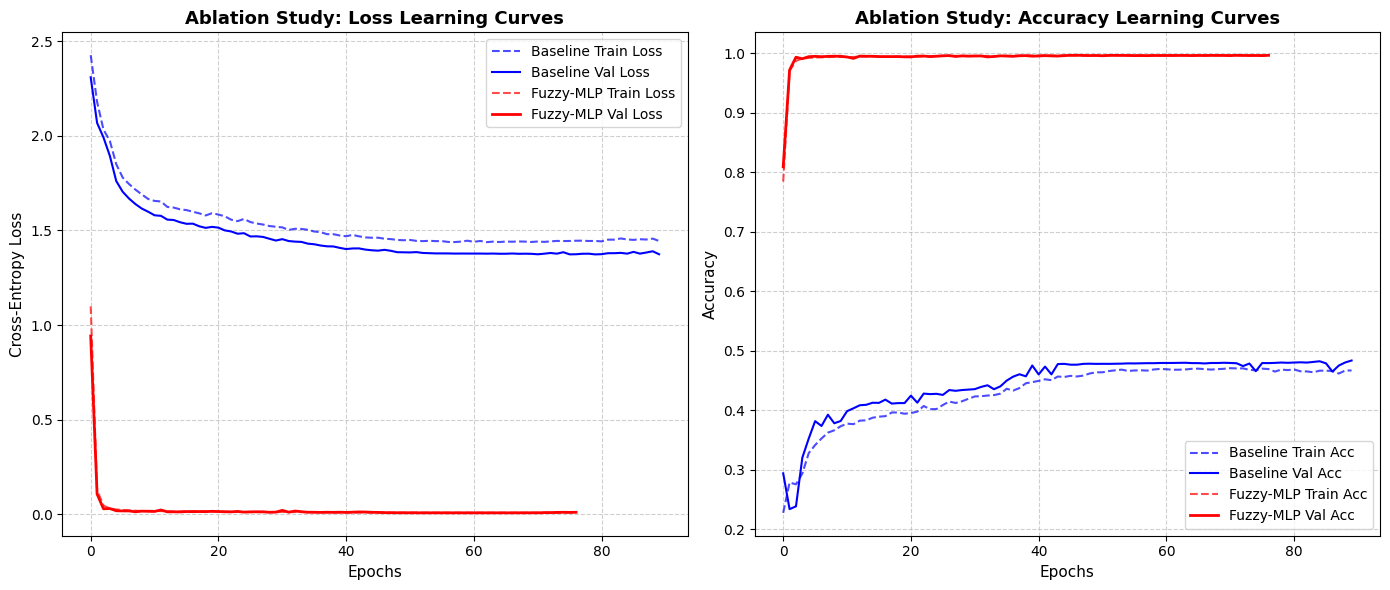

Ablation study learning curves saved successfully as 'ablation_study_learning_curves.png'!


In [ ]:

# =====================================================
# ABLATION STUDY: FUZZY + MLP vs. BASELINE MLP (NO FUZZY)
# =====================================================
import time

print("\n========================================")
print("STARTING ABLATION STUDY: FUZZY-MLP vs. BASELINE-MLP")
print("========================================")

# Use the best seed configuration for fair comparison
ablation_seed = 123
random.seed(ablation_seed)
np.random.seed(ablation_seed)
torch.manual_seed(ablation_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(ablation_seed)

# 1. Data Splits & Scaling (Shared across both models)
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X, y, test_size=0.2, random_state=ablation_seed, stratify=y
)
X_tr_a, X_val_a, y_tr_a, y_val_a = train_test_split(
    X_train_a, y_train_a, test_size=0.125, random_state=ablation_seed, stratify=y_train_a
)

scaler_a = RobustScaler()
X_tr_scaled = scaler_a.fit_transform(X_tr_a)
X_val_scaled = scaler_a.transform(X_val_a)
X_test_scaled = scaler_a.transform(X_test_a)

# 2. Variant A: Baseline MLP (Using Standard Scaled Features directly, Dim = M)
X_tr_base = torch.tensor(X_tr_scaled, dtype=torch.float32).to(device)
X_val_base = torch.tensor(X_val_scaled, dtype=torch.float32).to(device)
X_test_base = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)

y_tr_t = torch.tensor(y_tr_a, dtype=torch.long).to(device)
y_val_t = torch.tensor(y_val_a, dtype=torch.long).to(device)
y_test_t = torch.tensor(y_test_a, dtype=torch.long).to(device)

# 3. Variant B: Proposed Fuzzy-MLP (Using Interval Type-2 Fuzzy Expansion, Dim = 4M)
centers_a = np.median(X_tr_scaled, axis=0)
scales_a = np.std(X_tr_scaled, axis=0) + 1e-6

def ablation_fuzzy_transform(arr):
    features = []
    for i in range(arr.shape[1]):
        x = (arr[:, i] - centers_a[i]) / scales_a[i]
        lower = np.exp(-(x ** 2) / 0.7)
        upper = np.exp(-(x ** 2) / 0.3)
        pos = 1 / (1 + np.exp(-x))
        neg = 1 - pos
        features += [lower, upper, pos, neg]
    return np.stack(features, axis=1)

X_tr_fuzz = ablation_fuzzy_transform(X_tr_scaled)
X_val_fuzz = ablation_fuzzy_transform(X_val_scaled)
X_test_fuzz = ablation_fuzzy_transform(X_test_scaled)

X_tr_fuzz_t = torch.tensor(X_tr_fuzz, dtype=torch.float32).to(device)
X_val_fuzz_t = torch.tensor(X_val_fuzz, dtype=torch.float32).to(device)
X_test_fuzz_t = torch.tensor(X_test_fuzz, dtype=torch.float32).to(device)

# Class Weights
weights_a = compute_class_weight(class_weight="balanced", classes=np.unique(y_tr_a), y=y_tr_a)
weights_a_t = torch.tensor(weights_a, dtype=torch.float32).to(device)

# =====================================================
# TRAINING FUNCTION FOR ABLATION MODELS
# =====================================================
def train_ablation_model(X_tr_tensor, X_val_tensor, X_test_tensor, input_dim, model_name):
    print(f"\nTraining {model_name} (Input Dim: {input_dim})...")

    model = BF_IT2FIDS(input_dim=input_dim, num_classes=len(np.unique(y))).to(device)
    criterion = nn.CrossEntropyLoss(weight=weights_a_t)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=60)

    epochs = 100
    batch_size = 4096
    patience = 10
    patience_counter = 0
    best_val_loss = float('inf')
    best_state = None

    train_loss_hist, val_loss_hist = [], []
    train_acc_hist, val_acc_hist = [], []

    start_time = time.time()
    for epoch in range(epochs):
        model.train()
        total_loss = 0
        correct_train, total_train = 0, 0

        for i in range(0, len(X_tr_tensor), batch_size):
            xb = X_tr_tensor[i:i+batch_size]
            yb = y_tr_t[i:i+batch_size]

            optimizer.zero_grad()
            out = model(xb)
            loss = criterion(out, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            total_loss += loss.item()
            preds_train = torch.argmax(out, dim=1)
            correct_train += (preds_train == yb).sum().item()
            total_train += yb.size(0)

        scheduler.step()

        model.eval()
        with torch.no_grad():
            val_logits = model(X_val_tensor)
            val_loss = criterion(val_logits, y_val_t).item()
            val_preds = torch.argmax(val_logits, dim=1)
            val_acc = (val_preds == y_val_t).sum().item() / y_val_t.size(0)

        train_loss_hist.append(total_loss / (len(X_tr_tensor) / batch_size))
        val_loss_hist.append(val_loss)
        train_acc_hist.append(correct_train / total_train)
        val_acc_hist.append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {k: v.cpu() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                break

    training_time = time.time() - start_time
    model.load_state_dict({k: v.to(device) for k, v in best_state.items()})

    model.eval()
    with torch.no_grad():
        test_logits = model(X_test_tensor)
        test_preds = torch.argmax(test_logits, dim=1).cpu().numpy()
        test_probs = F.softmax(test_logits, dim=1)
        test_acc = accuracy_score(y_test_a, test_preds)

    report = classification_report(y_test_a, test_preds, output_dict=True, zero_division=0)
    macro_f1 = report['macro avg']['f1-score']

    return {
        "model": model_name,
        "accuracy": test_acc,
        "macro_f1": macro_f1,
        "training_time": training_time,
        "train_loss": train_loss_hist,
        "val_loss": val_loss_hist,
        "train_acc": train_acc_hist,
        "val_acc": val_acc_hist
    }

# Execute Baseline and Proposed Fuzzy Models
result_baseline = train_ablation_model(X_tr_base, X_val_base, X_test_base, X_tr_scaled.shape[1], "Baseline MLP (No Fuzzy)")
result_fuzzy = train_ablation_model(X_tr_fuzz_t, X_val_fuzz_t, X_test_fuzz_t, X_tr_fuzz.shape[1], "BF-IT2FIDS (Ours - Fuzzy + MLP)")

# =====================================================
# RENDER ABLATION COMPARISON TABLE
# =====================================================
print("\n========================================")
print("ABLATION STUDY PERFORMANCE SUMMARY TABLE")
print("========================================")
print(f"{'Model Architecture':<35} | {'Input Dim':<10} | {'Test Accuracy':<15} | {'Macro F1':<10} | {'Time (s)':<10}")
print("-" * 85)
print(f"{'Baseline MLP (No Fuzzy)':<35} | {X_tr_scaled.shape[1]:<10} | {result_baseline['accuracy']*100:.2f}%          | {result_baseline['macro_f1']:.4f}     | {result_baseline['training_time']:.1f}s")
print(f"{'BF-IT2FIDS (Ours - Fuzzy + MLP)':<35} | {X_tr_fuzz.shape[1]:<10} | {result_fuzzy['accuracy']*100:.2f}%          | {result_fuzzy['macro_f1']:.4f}     | {result_fuzzy['training_time']:.1f}s")
print("========================================")

# =====================================================
# PLOT LEARNING CURVES FOR BOTH ABLATION MODELS
# =====================================================
plt.figure(figsize=(14, 6))

# Loss Curves
plt.subplot(1, 2, 1)
plt.plot(result_baseline['train_loss'], label="Baseline Train Loss", linestyle="--", color="blue", alpha=0.7)
plt.plot(result_baseline['val_loss'], label="Baseline Val Loss", linestyle="-", color="blue")
plt.plot(result_fuzzy['train_loss'], label="Fuzzy-MLP Train Loss", linestyle="--", color="red", alpha=0.7)
plt.plot(result_fuzzy['val_loss'], label="Fuzzy-MLP Val Loss", linestyle="-", color="red", linewidth=2)
plt.title("Ablation Study: Loss Learning Curves", fontsize=13, weight="bold")
plt.xlabel("Epochs", fontsize=11)
plt.ylabel("Cross-Entropy Loss", fontsize=11)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

# Accuracy Curves
plt.subplot(1, 2, 2)
plt.plot(result_baseline['train_acc'], label="Baseline Train Acc", linestyle="--", color="blue", alpha=0.7)
plt.plot(result_baseline['val_acc'], label="Baseline Val Acc", linestyle="-", color="blue")
plt.plot(result_fuzzy['train_acc'], label="Fuzzy-MLP Train Acc", linestyle="--", color="red", alpha=0.7)
plt.plot(result_fuzzy['val_acc'], label="Fuzzy-MLP Val Acc", linestyle="-", color="red", linewidth=2)
plt.title("Ablation Study: Accuracy Learning Curves", fontsize=13, weight="bold")
plt.xlabel("Epochs", fontsize=11)
plt.ylabel("Accuracy", fontsize=11)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig("ablation_study_learning_curves.png", dpi=300)
plt.show()
print("Ablation study learning curves saved successfully as 'ablation_study_learning_curves.png'!")

Using device: cuda
DATA SHAPE: (157800, 63)
TARGET USED: Attack_type
NUM CLASSES: 15
7     24301
4     14498
2     14090
10    10925
1     10561
11    10311
12    10269
3     10247
0     10195
13    10076
9     10071
14    10052
8      9989
6      1214
5      1001
Name: count, dtype: int64
Running training & evaluation with seed: 42...
Running training & evaluation with seed: 100...
Running training & evaluation with seed: 2026...
Running training & evaluation with seed: 7...
Running training & evaluation with seed: 123...
Running training & evaluation with seed: 999...
Running training & evaluation with seed: 2024...
Running training & evaluation with seed: 555...
Running training & evaluation with seed: 888...
Running training & evaluation with seed: 77...

BEST SEED IDENTIFIED: 123 (Test Accuracy: 0.9968)

PPNN FINAL (BEST SEED 123)
Accuracy: 0.9968

Classification Report:

              precision    recall  f1-score   support

           0     0.9995    0.9853    0.9923      2039
 

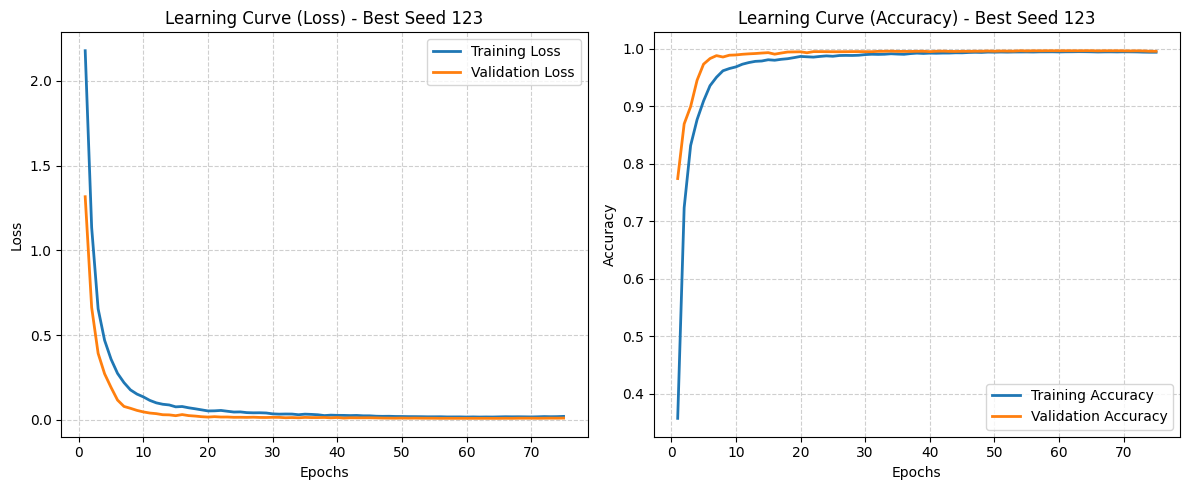

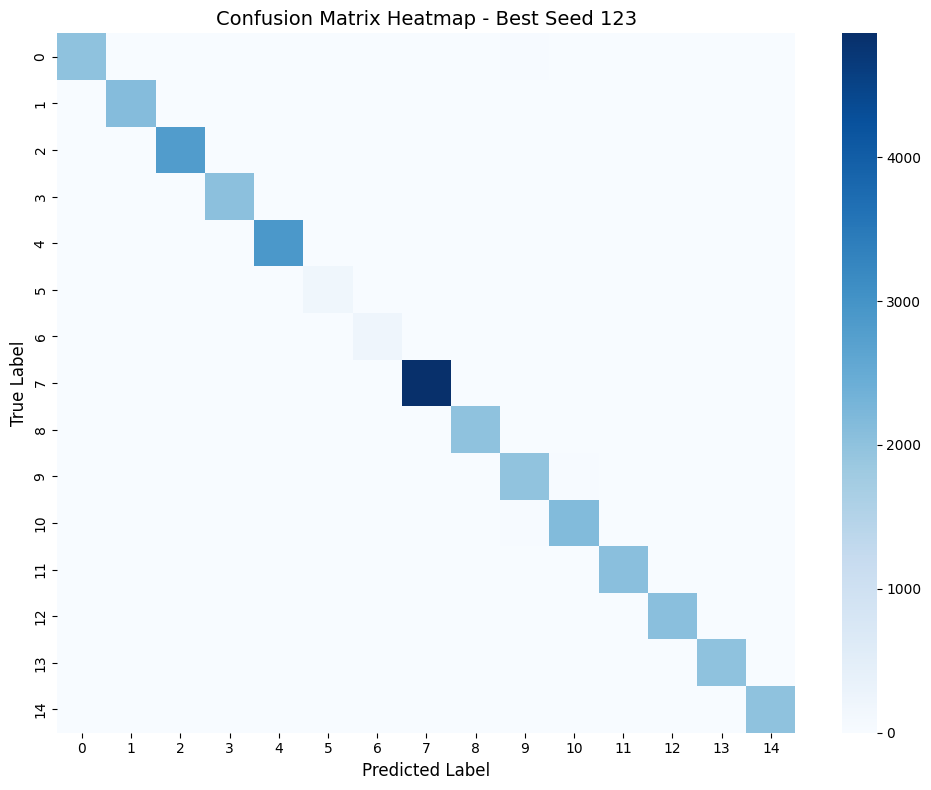


10-SEED FINAL PERFORMANCE SUMMARY
Seed 42   | Train Acc: 0.9960 | Test Acc: 0.9963
Seed 100  | Train Acc: 0.9964 | Test Acc: 0.9966
Seed 2026 | Train Acc: 0.9965 | Test Acc: 0.9962
Seed 7    | Train Acc: 0.9957 | Test Acc: 0.9953
Seed 123  | Train Acc: 0.9966 | Test Acc: 0.9968
Seed 999  | Train Acc: 0.9962 | Test Acc: 0.9963
Seed 2024 | Train Acc: 0.9964 | Test Acc: 0.9965
Seed 555  | Train Acc: 0.9962 | Test Acc: 0.9951
Seed 888  | Train Acc: 0.9967 | Test Acc: 0.9962
Seed 77   | Train Acc: 0.9958 | Test Acc: 0.9956
----------------------------------------
Mean Train Accuracy : 0.9962
Mean Test Accuracy  : 0.9961
Std Test Accuracy   : 0.0006


In [ ]:

# =====================================================
# 1. IMPORTS
# =====================================================
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.preprocessing import LabelEncoder, RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# =====================================================
# 2. DEVICE
# =====================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# =====================================================
# 3. LOAD DATASET (SAFE SEARCH)
# =====================================================
base_path = "/kaggle/input/edge-iiotset-dataset"
file_name = "ML-EdgeIIoT-dataset.csv"

data_path = None
for root, _, files in os.walk(base_path):
    if file_name in files:
        data_path = os.path.join(root, file_name)
        break

if data_path is None:
    raise FileNotFoundError("Dataset not found!")

data = pd.read_csv(data_path, low_memory=False)
print("DATA SHAPE:", data.shape)

# =====================================================
# 4. TARGET FIX (IMPORTANT FIX)
# =====================================================
if "Attack_type" in data.columns:
    target = "Attack_type"
elif "Attack_cat" in data.columns:
    target = "Attack_cat"
elif "Attack_label" in data.columns:
    print("⚠ WARNING: Only binary label found. Switching to multiclass NOT available.")
    target = "Attack_label"
else:
    raise ValueError("No valid target column found!")

print("TARGET USED:", target)

y = data[target]
X = data.drop(columns=[target])

# =====================================================
# 5. CLEANING
# =====================================================
X = X.fillna(0)

for col in X.columns:
    if X[col].dtype == "object":
        X[col] = LabelEncoder().fit_transform(X[col].astype(str))

# Encode labels properly (MULTICLASS SAFE)
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

print("NUM CLASSES:", len(np.unique(y)))
print(pd.Series(y).value_counts())

# =====================================================
# 10-SEED CONFIGURATION
# =====================================================
SEEDS = [42, 100, 2026, 7, 123, 999, 2024, 555, 888, 77]
seed_results = []

for seed in SEEDS:
    print(f"Running training & evaluation with seed: {seed}...")

    # Set all random seeds for reproducibility
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # =====================================================
    # 6. TRAIN / TEST SPLIT (STRATIFIED)
    # =====================================================
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=seed,
        stratify=y
    )

    # Create a validation split from the training set for Early Stopping
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_train, y_train,
        test_size=0.125, # Yields a 70% train, 10% val, 20% test split layout
        random_state=seed,
        stratify=y_train
    )

    # =====================================================
    # 7. SCALING (NO DATA LEAKAGE)
    # =====================================================
    scaler = RobustScaler()
    X_tr = scaler.fit_transform(X_tr)
    X_val = scaler.transform(X_val)
    X_test = scaler.transform(X_test)

    # =====================================================
    # 8. FUZZY FEATURE ENGINEERING (STABLE)
    # =====================================================
    centers = np.median(X_tr, axis=0)
    scales = np.std(X_tr, axis=0) + 1e-6

    def fuzzy_transform(arr):
        features = []
        for i in range(arr.shape[1]):
            x = (arr[:, i] - centers[i]) / scales[i]

            lower = np.exp(-(x ** 2) / 0.7)
            upper = np.exp(-(x ** 2) / 0.3)

            pos = 1 / (1 + np.exp(-x))
            neg = 1 - pos

            features += [lower, upper, pos, neg]

        return np.stack(features, axis=1)

    X_tr_f = fuzzy_transform(X_tr)
    X_val_f = fuzzy_transform(X_val)
    X_test_f = fuzzy_transform(X_test)

    # =====================================================
    # 9. TENSORS
    # =====================================================
    X_train_t = torch.tensor(X_tr_f, dtype=torch.float32).to(device)
    X_val_t = torch.tensor(X_val_f, dtype=torch.float32).to(device)
    X_test_t = torch.tensor(X_test_f, dtype=torch.float32).to(device)

    y_train_t = torch.tensor(y_tr, dtype=torch.long).to(device)
    y_val_t = torch.tensor(y_val, dtype=torch.long).to(device)
    y_test_t = torch.tensor(y_test, dtype=torch.long).to(device)

    # =====================================================
    # 10. CLASS WEIGHTS (IMPORTANT FOR IDS)
    # =====================================================
    weights = compute_class_weight(
        class_weight="balanced",
        classes=np.unique(y_tr),
        y=y_tr
    )

    weights = torch.tensor(weights, dtype=torch.float32).to(device)

    # =====================================================
    # 11. PROGRESSIVE PRIME FUZZY NEURAL NETWORK (PPNN) ARCHITECTURE
    # Layer sizes strictly match prime numbers: 67 -> 131 -> 257 -> 131 -> 67
    # =====================================================
    class ProgressivePrimeFuzzyNN(nn.Module):
        def __init__(self, input_dim, num_classes):
            super().__init__()
            self.net = nn.Sequential(
                # Expansion Phase (Prime Dimensions)
                nn.Linear(input_dim, 67),
                nn.LayerNorm(67),
                nn.ReLU(),
                nn.Dropout(0.2),

                nn.Linear(67, 131),
                nn.LayerNorm(131),
                nn.ReLU(),
                nn.Dropout(0.2),

                # Latent Peak Layer (Max Capacity Prime Dimension)
                nn.Linear(131, 257),
                nn.LayerNorm(257),
                nn.ReLU(),
                nn.Dropout(0.2),

                # Contraction Phase (Prime Dimensions)
                nn.Linear(257, 131),
                nn.LayerNorm(131),
                nn.ReLU(),
                nn.Dropout(0.2),

                nn.Linear(131, 67),
                nn.LayerNorm(67),
                nn.ReLU(),
                nn.Dropout(0.2),

                # Classification Output Head
                nn.Linear(67, num_classes)
            )

        def forward(self, x):
            return self.net(x)

    model = ProgressivePrimeFuzzyNN(
        input_dim=X_tr_f.shape[1],
        num_classes=len(np.unique(y))
    ).to(device)

    # =====================================================
    # 12. LOSS + OPTIMIZER
    # =====================================================
    criterion = nn.CrossEntropyLoss(weight=weights)

    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=60)

    # =====================================================
    # 13. TRAINING LOOP WITH EARLY STOPPING & HISTORY LOGGING
    # =====================================================
    epochs = 100
    batch_size = 4096

    patience = 10
    patience_counter = 0
    best_val_loss = float('inf')
    best_model_state = None

    train_loss_history = []
    val_loss_history = []
    train_acc_history = []
    val_acc_history = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        correct_train = 0
        total_train = 0

        for i in range(0, len(X_train_t), batch_size):
            xb = X_train_t[i:i+batch_size]
            yb = y_train_t[i:i+batch_size]

            optimizer.zero_grad()
            out = model(xb)
            loss = criterion(out, yb)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

            optimizer.step()
            total_loss += loss.item()

            preds_train = torch.argmax(out, dim=1)
            correct_train += (preds_train == yb).sum().item()
            total_train += yb.size(0)

        scheduler.step()

        model.eval()
        with torch.no_grad():
            val_logits = model(X_val_t)
            val_loss = criterion(val_logits, y_val_t).item()
            val_preds = torch.argmax(val_logits, dim=1)
            correct_val = (val_preds == y_val_t).sum().item()
            val_acc = correct_val / y_val_t.size(0)

        epoch_train_loss = total_loss / (len(X_train_t) / batch_size)
        epoch_train_acc = correct_train / total_train

        train_loss_history.append(epoch_train_loss)
        val_loss_history.append(val_loss)
        train_acc_history.append(epoch_train_acc)
        val_acc_history.append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_state = {k: v.cpu() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                break

    if best_model_state is not None:
        model.load_state_dict({k: v.to(device) for k, v in best_model_state.items()})

    # =====================================================
    # 14. EVALUATION
    # =====================================================
    model.eval()

    with torch.no_grad():
        train_final_logits = model(X_train_t)
        train_final_preds = torch.argmax(train_final_logits, dim=1).cpu().numpy()
        final_train_acc = accuracy_score(y_tr.cpu().numpy() if isinstance(y_tr, torch.Tensor) else y_tr, train_final_preds)

        logits = model(X_test_t)
        probs = F.softmax(logits, dim=1)

        preds = torch.argmax(probs, dim=1).cpu().numpy()
        risk = torch.max(probs, dim=1).values.cpu().numpy()

    test_acc = accuracy_score(y_test, preds)

    seed_results.append({
        "seed": seed,
        "accuracy": test_acc,
        "train_accuracy": final_train_acc,
        "preds": preds,
        "y_test": y_test,
        "risk": risk,
        "train_loss": train_loss_history,
        "val_loss": val_loss_history,
        "train_acc": train_acc_history,
        "val_acc": val_acc_history
    })

# =====================================================
# 15. FIND BEST SEED & RENDER RESULTS ONLY FOR IT
# =====================================================
best_result = max(seed_results, key=lambda x: x["accuracy"])
best_seed = best_result["seed"]

print(f"\n========================================")
print(f"BEST SEED IDENTIFIED: {best_seed} (Test Accuracy: {best_result['accuracy']:.4f})")
print(f"========================================")

print("\n==============================")
print(f"PPNN FINAL (BEST SEED {best_seed})")
print("==============================")

print(f"Accuracy: {best_result['accuracy']:.4f}")

print("\nClassification Report:\n")
print(classification_report(best_result['y_test'], best_result['preds'], digits=4))

print("\nSample Risk Scores (4 decimal places):")
print([f"{val:.4f}" for val in best_result['risk'][:10]])

# Plot Learning Curves for Best Seed
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, len(best_result['train_loss']) + 1), best_result['train_loss'], label="Training Loss", linewidth=2)
plt.plot(range(1, len(best_result['val_loss']) + 1), best_result['val_loss'], label="Validation Loss", linewidth=2)
plt.title(f"Learning Curve (Loss) - Best Seed {best_seed}", fontsize=12)
plt.xlabel("Epochs", fontsize=10)
plt.ylabel("Loss", fontsize=10)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.subplot(1, 2, 2)
plt.plot(range(1, len(best_result['train_acc']) + 1), best_result['train_acc'], label="Training Accuracy", linewidth=2)
plt.plot(range(1, len(best_result['val_acc']) + 1), best_result['val_acc'], label="Validation Accuracy", linewidth=2)
plt.title(f"Learning Curve (Accuracy) - Best Seed {best_seed}", fontsize=12)
plt.xlabel("Epochs", fontsize=10)
plt.ylabel("Accuracy", fontsize=10)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig(f"learning_curve_best_seed_{best_seed}.png", dpi=300)
plt.show()

# Plot Confusion Matrix Heatmap for Best Seed
cm = confusion_matrix(best_result['y_test'], best_result['preds'])
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=False, fmt="d", cmap="Blues", cbar=True)
plt.title(f"Confusion Matrix Heatmap - Best Seed {best_seed}", fontsize=14)
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.tight_layout()
plt.savefig(f"confusion_matrix_best_seed_{best_seed}.png", dpi=300)
plt.show()

# =====================================================
# 16. 10-SEED PERFORMANCE SUMMARY REPORT
# =====================================================
print("\n========================================")
print("10-SEED FINAL PERFORMANCE SUMMARY")
print("========================================")
accuracies = [res["accuracy"] for res in seed_results]
train_accuracies = [res["train_accuracy"] for res in seed_results]

for res in seed_results:
    print(f"Seed {res['seed']:<4} | Train Acc: {res['train_accuracy']:.4f} | Test Acc: {res['accuracy']:.4f}")

print("----------------------------------------")
print(f"Mean Train Accuracy : {np.mean(train_accuracies):.4f}")
print(f"Mean Test Accuracy  : {np.mean(accuracies):.4f}")
print(f"Std Test Accuracy   : {np.std(accuracies):.4f}")
print("========================================")


STARTING 4-WAY ABLATION STUDY ACROSS 10 SEEDS (200 EPOCHS MAX)

--- Evaluating Model: MLP ---
 -> Seed 42    | Test Acc: 61.69% | Macro F1: 0.5386 | Epochs Run: 214
 -> Seed 100   | Test Acc: 62.47% | Macro F1: 0.5407 | Epochs Run: 202
 -> Seed 2026  | Test Acc: 62.40% | Macro F1: 0.5460 | Epochs Run: 254
 -> Seed 7     | Test Acc: 62.79% | Macro F1: 0.5579 | Epochs Run: 195
 -> Seed 123   | Test Acc: 61.56% | Macro F1: 0.5409 | Epochs Run: 204
 -> Seed 999   | Test Acc: 52.49% | Macro F1: 0.4976 | Epochs Run: 117
 -> Seed 2024  | Test Acc: 62.09% | Macro F1: 0.5393 | Epochs Run: 208
 -> Seed 555   | Test Acc: 61.76% | Macro F1: 0.5392 | Epochs Run: 205
 -> Seed 888   | Test Acc: 61.94% | Macro F1: 0.5314 | Epochs Run: 205
 -> Seed 77    | Test Acc: 62.51% | Macro F1: 0.5392 | Epochs Run: 208

[Summary] MLP -> Mean Acc: 61.17% (±2.92%) | Mean F1: 0.5371

--- Evaluating Model: Fuzzy MLP ---
 -> Seed 42    | Test Acc: 99.57% | Macro F1: 0.9921 | Epochs Run: 37
 -> Seed 100   | Test Acc:

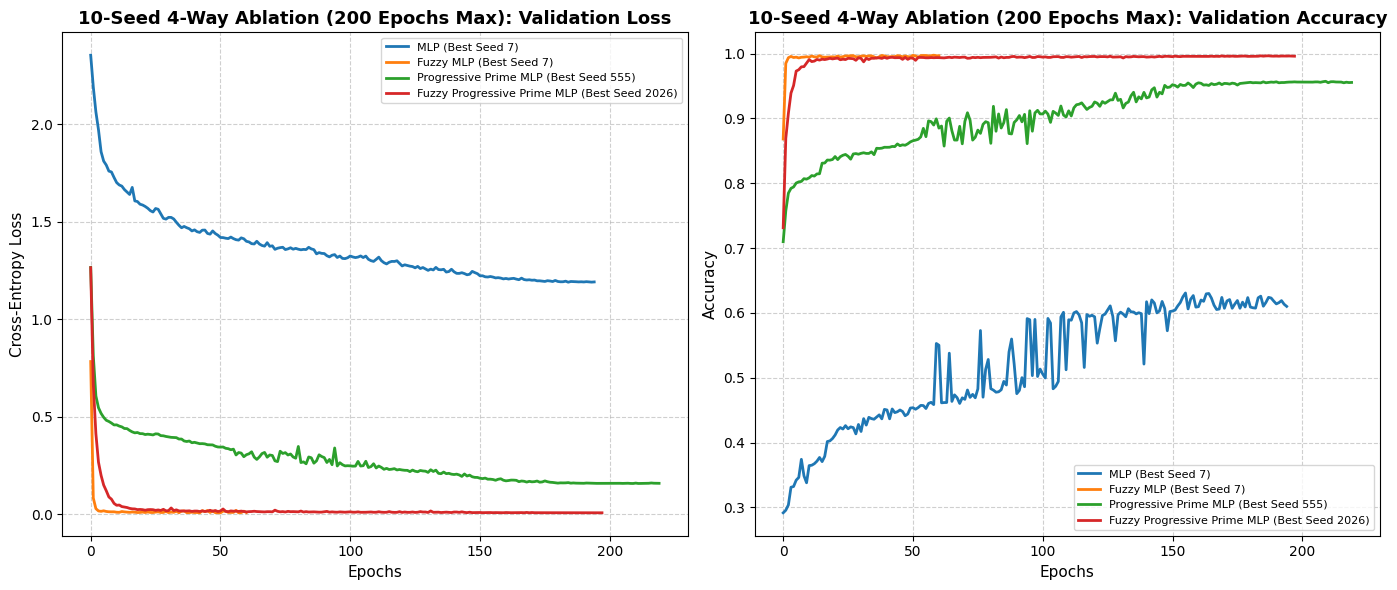

200-epoch 10-seed ablation curves saved successfully as 'four_way_200ep_10seed_ablation_learning_curves.png'!


In [ ]:
# =====================================================
# 4-WAY ABLATION STUDY ACROSS 10 SEEDS (200 EPOCHS + EARLY STOPPING)
# Models:
#   1. Simple MLP (Raw Features, Standard Topology)
#   2. Fuzzy MLP (Fuzzy Features, Standard Topology)
#   3. Progressive Prime MLP (Raw Features, Prime Bottleneck Topology - NO FUZZY)
#   4. Fuzzy Progressive Prime MLP (Fuzzy Features, Prime Bottleneck Topology - OURS)
# =====================================================

import time

print("\n========================================================")
print("STARTING 4-WAY ABLATION STUDY ACROSS 10 SEEDS (200 EPOCHS MAX)")
print("========================================================")

# ----------------------------------------------------
# 1. Define Architectures
# ----------------------------------------------------

class SimpleMLP(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )
    def forward(self, x):
        return self.net(x)


class FuzzyMLP(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )
    def forward(self, x):
        return self.net(x)


class ProgressivePrimeMLPRaw(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 67), nn.LayerNorm(67), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(67, 131), nn.LayerNorm(131), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(131, 257), nn.LayerNorm(257), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(257, 131), nn.LayerNorm(131), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(131, 67), nn.LayerNorm(67), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(67, num_classes)
        )
    def forward(self, x):
        return self.net(x)


class FuzzyProgressivePrimeMLPFuzzy(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 67), nn.LayerNorm(67), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(67, 131), nn.LayerNorm(131), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(131, 257), nn.LayerNorm(257), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(257, 131), nn.LayerNorm(131), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(131, 67), nn.LayerNorm(67), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(67, num_classes)
        )
    def forward(self, x):
        return self.net(x)


# ----------------------------------------------------
# 2. Evaluation Function Across the 10 SEEDS (200 Epochs + Early Stopping)
# ----------------------------------------------------
def evaluate_model_on_all_seeds(model_class, use_fuzzy, model_name):
    print(f"\n--- Evaluating Model: {model_name} ---")
    seed_accuracies = []
    seed_macro_f1s = []
    seed_times = []

    best_acc = -1
    best_metrics = None

    for seed in SEEDS:
        # Set all random seeds for absolute reproducibility
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)

        # 1. Stratified Split per Seed
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.2, random_state=seed, stratify=y
        )
        X_tr, X_val, y_tr, y_val = train_test_split(
            X_train, y_train, test_size=0.125, random_state=seed, stratify=y_train
        )

        # 2. Scaling
        scaler = RobustScaler()
        X_tr_s = scaler.fit_transform(X_tr)
        X_val_s = scaler.transform(X_val)
        X_test_s = scaler.transform(X_test)

        # 3. Feature Preparation (Raw vs Fuzzy)
        if use_fuzzy:
            centers = np.median(X_tr_s, axis=0)
            scales = np.std(X_tr_s, axis=0) + 1e-6

            def get_fuzzy(arr):
                feats = []
                for i in range(arr.shape[1]):
                    x = (arr[:, i] - centers[i]) / scales[i]
                    lower = np.exp(-(x ** 2) / 0.7)
                    upper = np.exp(-(x ** 2) / 0.3)
                    pos = 1 / (1 + np.exp(-x))
                    neg = 1 - pos
                    feats += [lower, upper, pos, neg]
                return np.stack(feats, axis=1)

            X_tr_f = get_fuzzy(X_tr_s)
            X_val_f = get_fuzzy(X_val_s)
            X_test_f = get_fuzzy(X_test_s)

            X_tr_t = torch.tensor(X_tr_f, dtype=torch.float32).to(device)
            X_val_t = torch.tensor(X_val_f, dtype=torch.float32).to(device)
            X_test_t = torch.tensor(X_test_f, dtype=torch.float32).to(device)
            input_dim = X_tr_f.shape[1]
        else:
            X_tr_t = torch.tensor(X_tr_s, dtype=torch.float32).to(device)
            X_val_t = torch.tensor(X_val_s, dtype=torch.float32).to(device)
            X_test_t = torch.tensor(X_test_s, dtype=torch.float32).to(device)
            input_dim = X_tr_s.shape[1]

        y_tr_t = torch.tensor(y_tr, dtype=torch.long).to(device)
        y_val_t = torch.tensor(y_val, dtype=torch.long).to(device)
        y_test_t = torch.tensor(y_test, dtype=torch.long).to(device)

        weights = compute_class_weight(class_weight="balanced", classes=np.unique(y_tr), y=y_tr)
        weights_t = torch.tensor(weights, dtype=torch.float32).to(device)

        # 4. Model Instantiation & Training (200 Epochs Max, Early Stopping Patience = 10)
        model = model_class(input_dim=input_dim, num_classes=len(np.unique(y))).to(device)
        criterion = nn.CrossEntropyLoss(weight=weights_t)
        optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=200)

        epochs = 300
        batch_size = 4096
        patience = 10
        patience_counter = 0
        best_val_loss = float('inf')
        best_state = None

        val_loss_hist, val_acc_hist = [], []
        start_time = time.time()

        for epoch in range(epochs):
            model.train()
            for i in range(0, len(X_tr_t), batch_size):
                xb = X_tr_t[i:i+batch_size]
                yb = y_tr_t[i:i+batch_size]

                optimizer.zero_grad()
                out = model(xb)
                loss = criterion(out, yb)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

            scheduler.step()

            model.eval()
            with torch.no_grad():
                val_logits = model(X_val_t)
                val_loss = criterion(val_logits, y_val_t).item()
                val_preds = torch.argmax(val_logits, dim=1)
                val_acc = (val_preds == y_val_t).sum().item() / y_val_t.size(0)

            val_loss_hist.append(val_loss)
            val_acc_hist.append(val_acc)

            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_state = {k: v.cpu() for k, v in model.state_dict().items()}
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    break

        training_time = time.time() - start_time
        model.load_state_dict({k: v.to(device) for k, v in best_state.items()})

        model.eval()
        with torch.no_grad():
            test_logits = model(X_test_t)
            test_preds = torch.argmax(test_logits, dim=1).cpu().numpy()
            test_acc = accuracy_score(y_test, test_preds)

        report = classification_report(y_test, test_preds, output_dict=True, zero_division=0)
        macro_f1 = report['macro avg']['f1-score']

        seed_accuracies.append(test_acc)
        seed_macro_f1s.append(macro_f1)
        seed_times.append(training_time)

        print(f" -> Seed {seed:<5} | Test Acc: {test_acc*100:.2f}% | Macro F1: {macro_f1:.4f} | Epochs Run: {len(val_loss_hist)}")

        if test_acc > best_acc:
            best_acc = test_acc
            best_metrics = {
                "seed": seed,
                "accuracy": test_acc,
                "macro_f1": macro_f1,
                "val_loss": val_loss_hist,
                "val_acc": val_acc_hist
            }

    mean_acc = np.mean(seed_accuracies)
    std_acc = np.std(seed_accuracies)
    mean_f1 = np.mean(seed_macro_f1s)
    mean_time = np.mean(seed_times)

    print(f"\n[Summary] {model_name} -> Mean Acc: {mean_acc*100:.2f}% (±{std_acc*100:.2f}%) | Mean F1: {mean_f1:.4f}")

    return {
        "model_name": model_name,
        "mean_acc": mean_acc,
        "std_acc": std_acc,
        "mean_f1": mean_f1,
        "mean_time": mean_time,
        "best_metrics": best_metrics
    }


# ----------------------------------------------------
# 3. Execute 4-Way Evaluation Across the 10 Seeds (200 Epochs Max)
# ----------------------------------------------------
results_10seed_200ep = []

# 1. MLP (Raw Features, Standard Topology)
results_10seed_200ep.append(evaluate_model_on_all_seeds(SimpleMLP, use_fuzzy=False, model_name="MLP"))

# 2. Fuzzy MLP (Fuzzy Features, Standard Topology)
results_10seed_200ep.append(evaluate_model_on_all_seeds(FuzzyMLP, use_fuzzy=True, model_name="Fuzzy MLP"))

# 3. Progressive Prime MLP (Raw Features, Prime Bottleneck Topology)
results_10seed_200ep.append(evaluate_model_on_all_seeds(ProgressivePrimeMLPRaw, use_fuzzy=False, model_name="Progressive Prime MLP"))

# 4. Fuzzy Progressive Prime MLP (Fuzzy Features, Prime Bottleneck Topology - OURS)
results_10seed_200ep.append(evaluate_model_on_all_seeds(FuzzyProgressivePrimeMLPFuzzy, use_fuzzy=True, model_name="Fuzzy Progressive Prime MLP"))


# =====================================================
# 4. FINAL PAPER-READY COMPARATIVE SUMMARY TABLE
# =====================================================
print("\n==========================================================================")
print("10-SEED 4-WAY ABLATION STUDY FINAL PERFORMANCE TABLE (200 EPOCHS)")
print("==========================================================================")
print(f"{'Model Architecture':<36} | {'Mean Acc (%)':<14} | {'Mean Macro F1':<15} | {'Mean Time (s)':<12}")
print("-" * 83)
for res in results_10seed_200ep:
    print(f"{res['model_name']:<36} | {res['mean_acc']*100:.2f}% (±{res['std_acc']*100:.2f}%)   | {res['mean_f1']:.4f}          | {res['mean_time']:.1f}s")
print("==========================================================================")


# =====================================================
# 5. PLOT 4-WAY LEARNING CURVES FOR BEST SEEDS
# =====================================================
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
for res in results_10seed_200ep:
    bm = res['best_metrics']
    plt.plot(bm['val_loss'], label=f"{res['model_name']} (Best Seed {bm['seed']})", linewidth=2)
plt.title("10-Seed 4-Way Ablation (300 Epochs Max): Validation Loss", fontsize=13, weight="bold")
plt.xlabel("Epochs", fontsize=11)
plt.ylabel("Cross-Entropy Loss", fontsize=11)
plt.legend(fontsize=8)
plt.grid(True, linestyle="--", alpha=0.6)

plt.subplot(1, 2, 2)
for res in results_10seed_200ep:
    bm = res['best_metrics']
    plt.plot(bm['val_acc'], label=f"{res['model_name']} (Best Seed {bm['seed']})", linewidth=2)
plt.title("10-Seed 4-Way Ablation (300 Epochs Max): Validation Accuracy", fontsize=13, weight="bold")
plt.xlabel("Epochs", fontsize=11)
plt.ylabel("Accuracy", fontsize=11)
plt.legend(fontsize=8)
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig("four_way_200ep_10seed_ablation_learning_curves.png", dpi=300)
plt.show()
print("200-epoch 10-seed ablation curves saved successfully as 'four_way_200ep_10seed_ablation_learning_curves.png'!")